<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

-Juan Felipe Pacheco Gomez
-Isabella Ramirez Santamaria

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [51]:
# Importación de librerías estándar
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importación de modelos y métricas de Scikit-Learn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [52]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [53]:
from google.colab import drive, files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [54]:
os.chdir("/content/drive/MyDrive/TALLER IA ")

In [55]:
df=pd.read_csv("pymes_colombia.csv")
df.head()

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [56]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   empresa             250 non-null    object 
 1   ventas_anuales      250 non-null    float64
 2   empleados           250 non-null    int64  
 3   productividad       250 non-null    float64
 4   margen_operacional  250 non-null    float64
 5   endeudamiento       250 non-null    float64
 6   exportaciones_pct   250 non-null    float64
 7   inversion_tic       250 non-null    float64
 8   antiguedad          250 non-null    int64  
 9   crecimiento_ventas  250 non-null    float64
 10  sector              250 non-null    object 
 11  region              250 non-null    object 
dtypes: float64(7), int64(2), object(3)
memory usage: 23.6+ KB


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,"6,242.05",63.07,92.82,7.83,52.17,13.44,2.88,17.16,4.94
std,"5,547.71",56.20,39.72,7.27,17.29,18.34,2.97,9.98,10.93
min,66.70,2.00,8.34,-5.90,22.30,0.00,0.00,1.00,-17.30
25%,426.80,8.00,67.22,3.23,40.55,0.60,0.90,9.00,-0.20
50%,"4,694.50",55.00,87.17,6.85,47.10,3.85,1.70,16.00,3.20
75%,"10,491.10",81.75,114.13,12.00,59.15,16.45,3.08,26.00,8.25
max,"22,240.30",214.00,285.75,24.70,94.20,64.00,10.90,42.00,35.60


In [57]:
n_nulos = int(df.isnull().sum().sum())
conteo_sector = df['sector'].value_counts()

In [58]:
print("Valores faltantes en toda la base:", n_nulos)
print("\nConteo por sector:")
print(conteo_sector)

Valores faltantes en toda la base: 0

Conteo por sector:
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [59]:
analisis_descriptivo = """
###
1. No hay valores nulos, es decir, no es necesario realizar procesos de imputacion antes del analisis.

2. Las variables presentan escalaas muy diferentes, esto lo podemos ver en las ventas anuales ya que tiene una desviacion estandar de 5547,71, mientras que el margen operacional es de 7,27 y esto nos deja ver la diferncia dispersa de las magnitudes.

3. Es importante quye los algoritmos trabajen con distancia como kmeans porque las variuables con variables nuimericos mas grandes pueden dominar el calculo de las distancias, por eso es importante estandarizar las variables antes de agrupar.

4. si, en terminos de margen operacional y crecimiento de ventas donde podemos ver unos minimos significatuvos con respectos a los demas y asus maximos. en mnargen operacionbal este minimo refleja que pueden haber perdiudas en terminos operacionales y en crecimiento de ventas, el minimo es de 17,30 denora contreaccion significatiuva en algunas empresas. en maximo, el crecimiento en ventas tambien llega a representar cifras muy representativas de año a año en terminos nominales y reales.
"""

---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

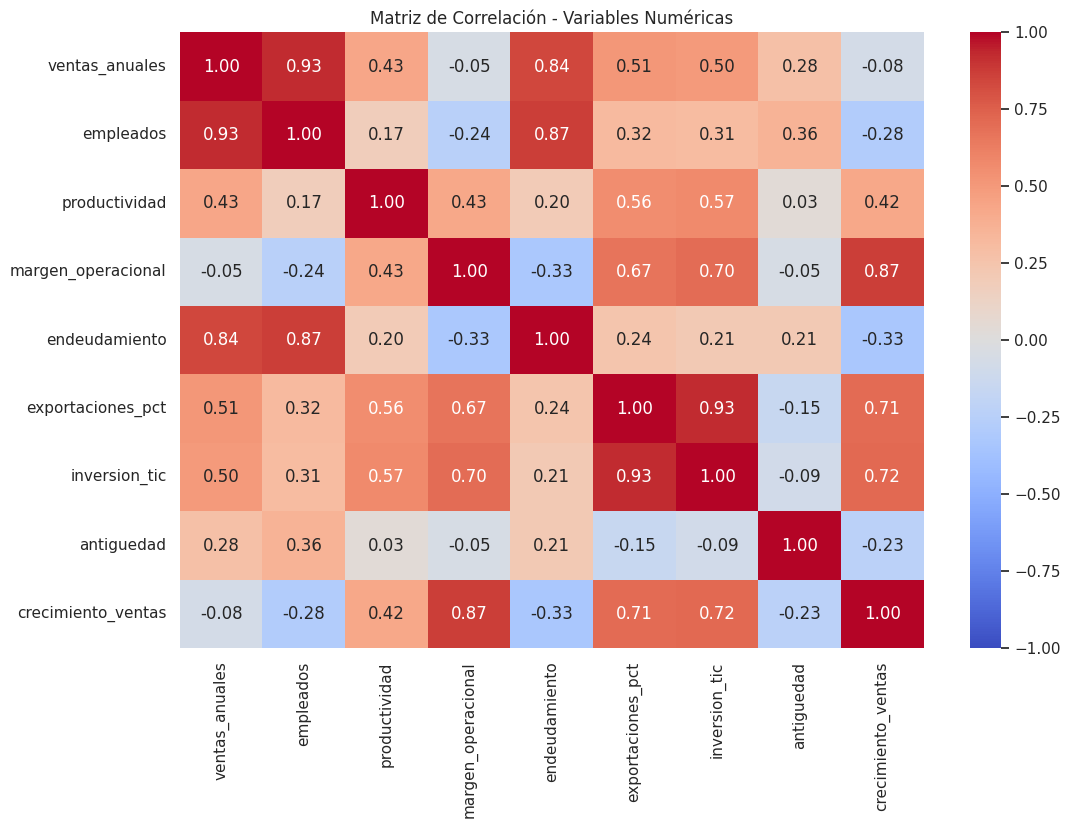

In [60]:
cols_numericas = df.select_dtypes(include=[np.number]).columns
matriz_corr = df[cols_numericas].corr()

sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlación - Variables Numéricas')
plt.show()

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [61]:
analisis_correlaciones = """
1. El par de variables más correlacionado positivamente es 'ventas_anuales' y 'empleados' (0.93). Esto tiene total sentido económico, ya que las empresas con mayor escala de producción y mayores ingresos requieren una mayor planta de personal para operar.

2. La correlación negativa más fuerte se observa entre 'antiguedad' y 'crecimiento_ventas' (aproximadamente -0.23). Esto cuenta una historia común en economía empresarial: las pymes más jóvenes tienden a registrar tasas de crecimiento de ventas más dinámicas y aceleradas, mientras que las empresas más antiguas entran en etapas de madurez con crecimientos más estables o moderados.

3. La relación entre 'ventas_anuales' y 'empleados' (0.93) es extremadamente fuerte, lo que sugiere una clara redundancia de información. Para el clustering, esto representa un problema ya que ambas variables aportarían casi la misma información de tamaño de empresa, ponderando doblemente esta dimensión en el cálculo de distancias euclidianas y sesgando la agrupación hacia el tamaño de la firma.
"""

---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [62]:
X = df.drop(columns=['empresa', 'sector', 'region'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:3])

[[-0.32215502 -0.01904015 -0.52760887 -0.08718771 -1.25608597 -0.58136218
  -0.33141033  1.59034862 -0.24214989]
 [-1.05399303 -1.01740016 -0.63255767 -0.32156328 -0.45632652 -0.72887165
  -0.56736155 -0.71945299 -0.66388602]
 [-0.32417792 -0.26863015 -0.00437858 -0.04582732 -0.07383287 -0.44477932
  -0.60106886  0.78693936  0.0420636 ]]


**3.2 ¿Y si no estandarizamos?** Vamos a comprobar con datos por qué el paso anterior no es opcional.

1. Guarda en `varianzas_sin_escalar` la **varianza de cada columna de `X`** (sin estandarizar), ordenada de mayor a menor. Imprímela.
2. Aplica K-Means **directamente sobre `X`, sin estandarizar**, con `n_clusters=5`, `init='k-means++'`, `n_init=10` y `random_state=42`. Guarda las etiquetas en `clusters_sin_escalar`.
3. Imprime cuántas empresas quedaron en cada grupo y el promedio de cada variable por grupo.

> El `k=5` de este punto es **provisional**: solo sirve para la comparación. En el Ejercicio 4 van a decidir el k de verdad.

In [63]:
varianzas_sin_escalar = X.var().sort_values(ascending=False)
print("Varianzas sin escalar:")
print(varianzas_sin_escalar)

kmeans_sin_escalar = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
clusters_sin_escalar = kmeans_sin_escalar.fit_predict(X)

print("\nEmpresas por grupo (sin estandarizar):")
df_temp = X.copy()
df_temp['cluster sin escalar'] = clusters_sin_escalar
print(df_temp['cluster sin escalar'].value_counts())

print("\nPromedio de cada variable por grupo:")
display(df_temp.groupby('cluster sin escalar').mean())

Varianzas sin escalar:
ventas_anuales       30,777,134.12
empleados                 3,158.95
productividad             1,577.51
exportaciones_pct           336.38
endeudamiento               298.94
crecimiento_ventas          119.45
antiguedad                   99.55
margen_operacional           52.82
inversion_tic                 8.84
dtype: float64

Empresas por grupo (sin estandarizar):
cluster sin escalar
1    79
2    72
4    53
0    25
3    21
Name: count, dtype: int64

Promedio de cada variable por grupo:


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster sin escalar,,,,,,,,,
0,"13,119.70",139.96,101.61,1.92,79.81,16.54,3.54,19.88,-3.28
1,361.92,6.42,67.86,4.61,39.46,0.45,0.63,7.34,2.25
2,"4,490.52",52.60,88.41,9.54,45.13,4.47,1.71,28.46,4.22
3,"17,568.06",177.05,101.01,-2.29,83.81,12.16,2.42,21.24,-10.13
4,"9,654.36",80.30,128.64,17.11,55.12,44.05,7.70,13.57,19.78


**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [64]:
analisis_escala = """
### TU TEXTO AQUÍ ###
"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

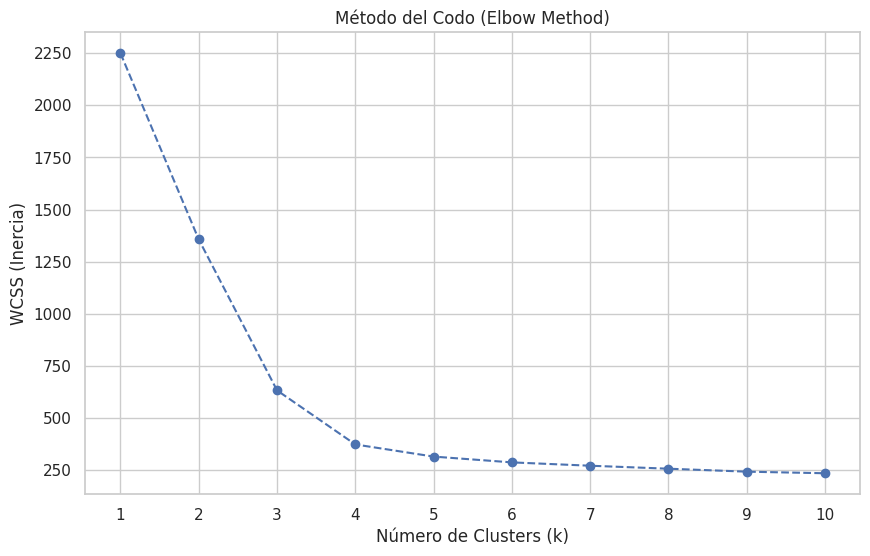

In [65]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Método del Codo (Elbow Method)')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('WCSS (Inercia)')
plt.xticks(range(1, 11))
plt.show()

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [66]:
"""
Al observar detenidamente la curva del WCSS, el primer cambio mas notorio a simple vista o el punto de inflexión evidente
se ubica en k = 3, donde el valor tiene una caida notoria desde aproximadamente 1,356 (en k=2) hasta 632.
Luego, se puede analizar otro quiebre muy pronunciado (el 'codo' definitivo) en k = 4, donde la se puede econtrar una
disminuye a 373.

A partir de k = 4 la curva se estabiliza significativamente (la ganancia en reducción de inmovilidad se vuelve muy marginal al pasar a k = 5 con 315 y k = 6 con 287).
Por lo tanto, los candidatos que se prefieren bajo este criterio son k = 3 y k = 4, quedando totalmente descartados
los valores de k mayores a 5 puesto que la inmovilidad empieza a decrecer de forma casi lineal.
"""

"\nAl observar detenidamente la curva del WCSS, el primer cambio mas notorio a simple vista o el punto de inflexión evidente \nse ubica en k = 3, donde el valor tiene una caida notoria desde aproximadamente 1,356 (en k=2) hasta 632. \nLuego, se puede analizar otro quiebre muy pronunciado (el 'codo' definitivo) en k = 4, donde la se puede econtrar una \ndisminuye a 373.\n\nA partir de k = 4 la curva se estabiliza significativamente (la ganancia en reducción de inmovilidad se vuelve muy marginal al pasar a k = 5 con 315 y k = 6 con 287). \nPor lo tanto, los candidatos que se prefieren bajo este criterio son k = 3 y k = 4, quedando totalmente descartados \nlos valores de k mayores a 5 puesto que la inmovilidad empieza a decrecer de forma casi lineal.\n"

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

Para k=2, Coeficiente de Silueta = 0.4530
Para k=3, Coeficiente de Silueta = 0.5826
Para k=4, Coeficiente de Silueta = 0.5568
Para k=5, Coeficiente de Silueta = 0.5555
Para k=6, Coeficiente de Silueta = 0.4697
Para k=7, Coeficiente de Silueta = 0.3854
Para k=8, Coeficiente de Silueta = 0.3031
Para k=9, Coeficiente de Silueta = 0.2211
Para k=10, Coeficiente de Silueta = 0.2286


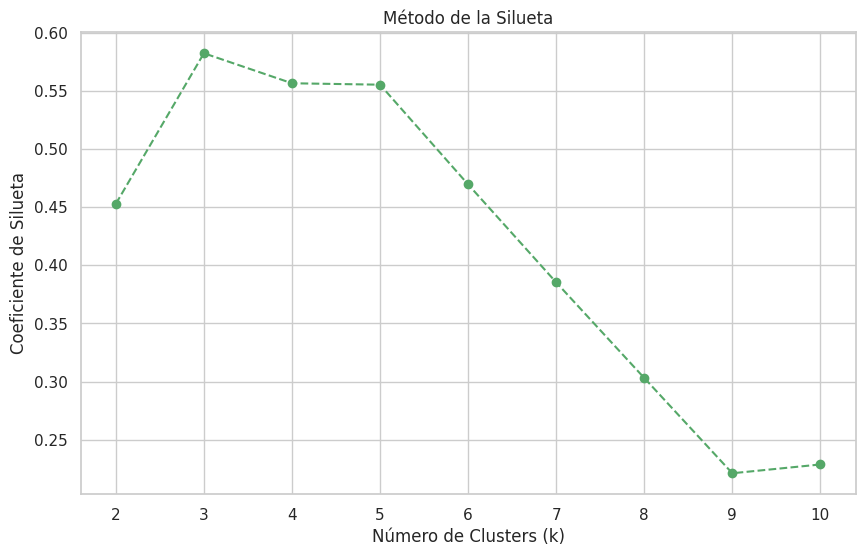

In [67]:
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"Para k={k}, Coeficiente de Silueta = {score:.4f}")


plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--', color='g')
plt.title('Método de la Silueta')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(range(2, 11))
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [68]:
analisis_silueta = """
Al analizar los resultados del Método de la Silueta, podemos extraer el siguiente analisis:

1. El coeficiente de silueta alcanza su punto máximo en k = 3 con un valor de 0.5826. En términos de agrupamiento, esto significa que tres grupos ofrecen la mejor combinación de cohesión (las empresas dentro de un mismo grupo son muy similares entre sí) y separación (los grupos están claramente distanciados entre sí).

2. Para k = 4 y k = 5, el coeficiente sigue siendo notablemente alto (0.5568 y 0.5555 respectivamente). Esto nos indica que una segmentación en 4 o 5 grupos sigue siendo metodológicamente sólida y muy defendible.

3. A partir de k = 6 se observa una caída drástica del coeficiente (por debajo de 0.47, llegando hasta 0.22 en k = 9), lo que evidencia que estructurar las PYMEs en 6 o más grupos genera solapamiento entre segmentos o fragmentaciones artificiales de grupos que por naturaleza deberían estar juntos.

En conclusión, el resultado del Método de la Silueta coincide plenamente con los candidatos óptimos identificados en el Método del Codo (k = 3 y k = 4), eliminando cualquier tensión entre ambos criterios y dando un sustento estadístico idóneo para la toma de decisiones.
"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [69]:
k_optimo = 3

print("El equipo trabajará con k =", k_optimo)

El equipo trabajará con k = 3


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [70]:
justificacion_k = """
La elección de k = 3 clusters se basa en el análisis
multidimensional que equilibra la precision estadística con ç
la viabilidad práctica para Bancóldex y el MinCIT:

1. Consistencia Matemática: El análisis del WCSS (Método del Codo) muestra que el primer punto de quiebre
donde la inmovilidad disminuye de forma más sustancial y la opcion mas adecuada es en k = 3.
Al cruzarlo con el Método de la Silueta, este valor obtiene la puntuación más alta de toda la serie (0.5826),
garantizando que las empresas estarán agrupadas con la mayor cohesión interna y la menor superposición posible.

Por estas razones, k = 3 es la representacion de la realidad heterogénea de las pymes colombianas.
"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [71]:
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)


conteo_clusters = df['cluster_kmeans'].value_counts()
porcentajes_clusters = df['cluster_kmeans'].value_counts(normalize=True) * 100

print("Distribución del tejido empresarial por cluster:")
for cluster_id in sorted(conteo_clusters.index):
    print(f"Cluster {cluster_id}: {conteo_clusters[cluster_id]} empresas ({porcentajes_clusters[cluster_id]:.2f}%)")

Distribución del tejido empresarial por cluster:
Cluster 0: 57 empresas (22.80%)
Cluster 1: 149 empresas (59.60%)
Cluster 2: 44 empresas (17.60%)


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [72]:
columnas_analisis = list(X.columns) + ['cluster_kmeans']
perfil_clusters = df[columnas_analisis].groupby('cluster_kmeans').mean()

display(perfil_clusters)

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
1,"2,274.83",27.80,77.55,6.80,41.99,1.76,1.07,17.54,2.99
2,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

Coeficiente de Silueta Final: 0.5826


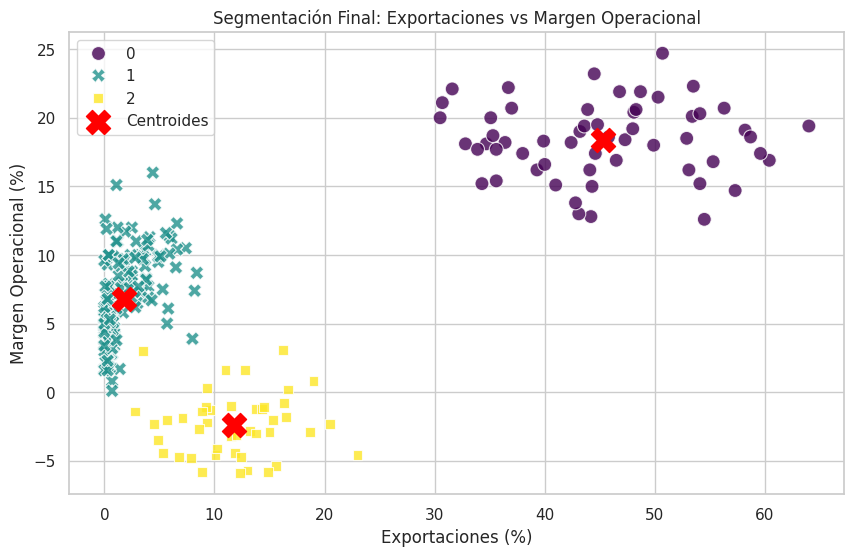

In [73]:
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print(f"Coeficiente de Silueta Final: {silueta_final:.4f}")

centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='exportaciones_pct',
    y='margen_operacional',
    hue='cluster_kmeans',
    palette='viridis',
    style='cluster_kmeans',
    s=100,
    alpha=0.8
)

plt.scatter(
    centroides_originales[:, 5],
    centroides_originales[:, 3],
    color='red',
    marker='X',
    s=300,
    label='Centroides'
)

plt.title('Segmentación Final: Exportaciones vs Margen Operacional')
plt.xlabel('Exportaciones (%)')
plt.ylabel('Margen Operacional (%)')
plt.legend()
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

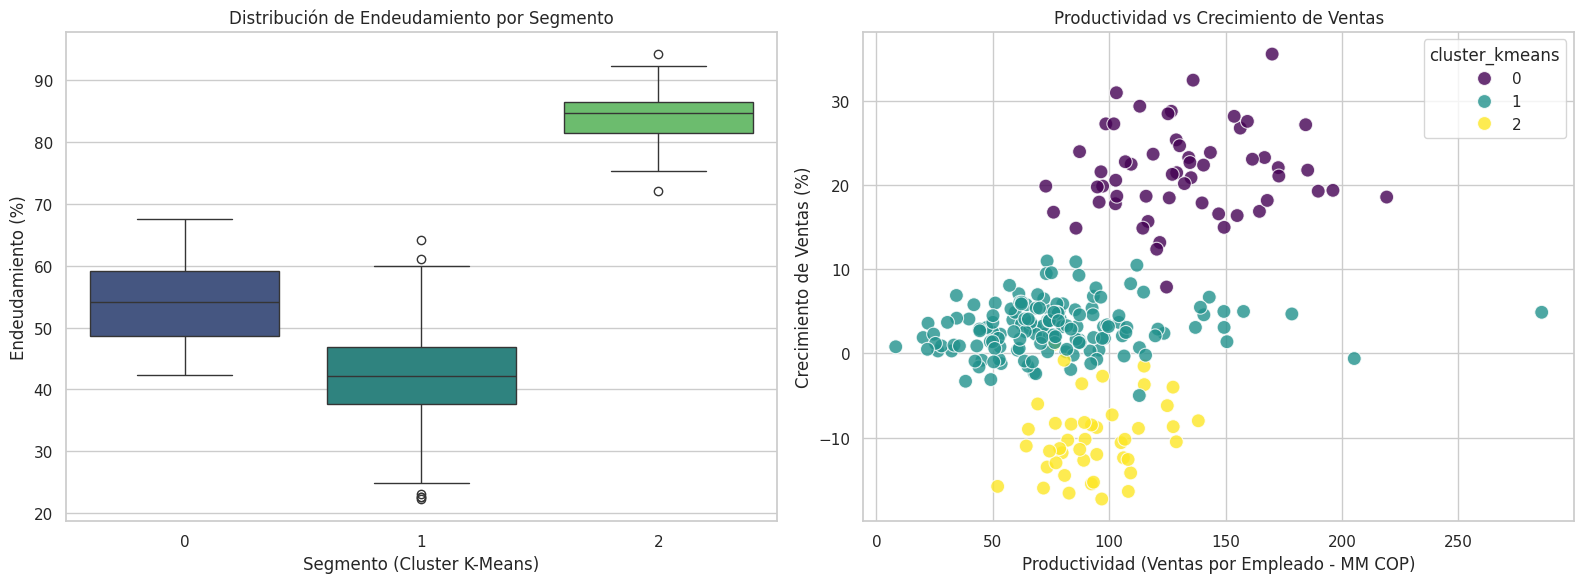

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.boxplot(
    data=df,
    x='cluster_kmeans',
    y='endeudamiento',
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribución de Endeudamiento por Segmento')
axes[0].set_xlabel('Segmento (Cluster K-Means)')
axes[0].set_ylabel('Endeudamiento (%)')


sns.scatterplot(
    data=df,
    x='productividad',
    y='crecimiento_ventas',
    hue='cluster_kmeans',
    palette='viridis',
    ax=axes[1],
    s=100,
    alpha=0.8
)
axes[1].set_title('Productividad vs Crecimiento de Ventas')
axes[1].set_xlabel('Productividad (Ventas por Empleado - MM COP)')
axes[1].set_ylabel('Crecimiento de Ventas (%)')

plt.tight_layout()
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [75]:
nombres_clusters = [
    "Pymes Exportadoras de Alto Rendimiento y Rentables",
    "Micro y Pequeñas Empresas de Mercado Interno en Consolidación",
    "Mediananas Empresas en Sobreesfuerzo Financiero y Reestructuración"
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Pymes Exportadoras de Alto Rendimiento y Rentables
Cluster 1: Micro y Pequeñas Empresas de Mercado Interno en Consolidación
Cluster 2: Mediananas Empresas en Sobreesfuerzo Financiero y Reestructuración


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [76]:
descripcion_clusters = """
### ANÁLISIS DETALLADO DE LOS SEGMENTOS EMPRESARIALES DE COLOMBIA (k=3)

1. CLUSTER 0: Pymes Exportadoras de Alto Rendimiento y Rentables
- Tamaño: Pymes de tamaño mediano con un promedio de ventas anuales de 9,696.40 millones de COP y un promedio de 75.95 empleados.
- Productividad y Rentabilidad: Poseen la productividad más alta con 132.31 millones de COP en ventas por empleado, y un excelente margen operacional promedio del 18.38%.
- Endeudamiento y Finanzas: Su nivel de endeudamiento es moderado y saludable, promediando el 54.09%.
- Tecnología e Internacionalización: Son el grupo líder en inserción global, exportando un promedio del 45.26% de sus ventas, impulsado por una robusta inversión promedio en tecnología (TIC) del 8.02% sobre sus ingresos.
- Antigüedad y Crecimiento: Tienen una trayectoria de 12.67 años en el mercado y un sobresaliente crecimiento de ventas del 21.55%.
- Peso en la muestra: Cuenta con 57 empresas (22.80% del tejido empresarial).
- Oportunidad/Problema: Su principal oportunidad reside en escalar su penetración internacional hacia nuevos mercados de exportación de alto valor agregado apalancando su alta competitividad tecnológica.

2. CLUSTER 1: Micro y Pequeñas Empresas de Mercado Interno en Consolidación
- Tamaño: Empresas de menor escala que promedian ventas anuales por 2,274.83 millones de COP y cuentan con 27.80 empleados en promedio.
- Productividad y Rentabilidad: Su productividad es la más baja de la muestra, registrando un promedio de 77.55 millones de COP por empleado, aunque mantienen una rentabilidad positiva pero modesta con un margen operacional del 6.80%.
- Endeudamiento y Finanzas: Es el grupo con el menor apalancamiento, reportando un nivel de endeudamiento promedio de solo el 41.99%.
- Tecnología e Internacionalización: Prácticamente no exportan (1.76% promedio) y tienen una baja inversión en herramientas tecnológicas (1.07%).
- Antigüedad y Crecimiento: Son las empresas más maduras de la muestra, con una antigüedad promedio de 17.54 años, pero con un crecimiento de ventas bastante modesto y ralentizado de apenas el 2.99%.
- Peso en la muestra: Es el grupo mayoritario, compuesto por 149 empresas (59.60% del tejido empresarial).
- Oportunidad/Problema: Su principal oportunidad es la modernización y digitalización de sus operaciones de mercado interno para revitalizar su crecimiento y elevar sus rezagados niveles de productividad.

3. CLUSTER 2: Medianas Empresas en Sobreesfuerzo Financiero y Reestructuración
- Tamaño: Son las empresas más grandes en tamaño y estructura, promediando ventas de 15,201.51 millones de COP y con la mayor nómina de la muestra (165.82 empleados en promedio).
- Productividad y Rentabilidad: Tienen una productividad media de 93.39 millones de COP por empleado, pero registran un preocupante margen operacional promedio negativo del -2.35% (pérdidas operativas).
- Endeudamiento y Finanzas: Enfrentan un grave problema de apalancamiento, con un preocupante endeudamiento promedio del 84.18%.
- Tecnología e Internacionalización: Exportan en promedio un 11.78% de sus ingresos y destinan el 1.95% de sus ventas a TIC.
- Antigüedad y Crecimiento: Poseen un promedio de 21.52 años en el mercado, pero atraviesan una severa contracción con una tasa de crecimiento de ventas negativa del -9.96%.
- Peso en la muestra: Cuenta con 44 empresas (17.60% del tejido empresarial).
- Oportunidad/Problema: Su principal y urgente reto es la intervención de rescate mediante reestructuración de pasivos financieros y optimización de márgenes operativos para evitar un riesgo inminente de insolvencia.
"""

---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [77]:
!pip install kmodes --quiet

In [78]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [79]:
df_mixto = df[list(X.columns) + ['sector']].copy()

indice_categoricas = [df_mixto.columns.get_loc('sector')]


matriz_mixta = df_mixto.values

scaler_mixto = StandardScaler()
matriz_mixta[:, :9] = scaler_mixto.fit_transform(matriz_mixta[:, :9])

encoder_sector = LabelEncoder()
matriz_mixta[:, 9] = encoder_sector.fit_transform(matriz_mixta[:, 9])

matriz_mixta = np.array(matriz_mixta, dtype=object)


print(matriz_mixta[:3])

[[-0.32215502244818983 -0.019040151619805316 -0.5276088744673821
  -0.0871877106365195 -1.256085972320208 -0.5813621752210532
  -0.3314103334258739 1.5903486182423119 -0.2421498859617228 1]
 [-1.0539930303588514 -1.0174001616470525 -0.6325576693059609
  -0.3215632768637223 -0.45632651776549416 -0.7288716547061528
  -0.5673615472156539 -0.7194529869340696 -0.6638860193192588 1]
 [-0.3241779217518744 -0.26863015412661706 -0.004378584815428655
  -0.04582731659642492 -0.07383286558715263 -0.4447793238459608
  -0.6010688634713367 0.7869393642679183 0.04206359521400809 1]]


**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [80]:
try:
    from kmodes.kprototypes import KPrototypes
except ModuleNotFoundError:
    !pip install kmodes --quiet
    from kmodes.kprototypes import KPrototypes

kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
df['cluster_kproto'] = kproto.fit_predict(matriz_mixta, categorical=indice_categoricas)

print("Distribución de empresas en K-Prototypes:")
print(df['cluster_kproto'].value_counts())

Distribución de empresas en K-Prototypes:
cluster_kproto
0    149
2     57
1     44
Name: count, dtype: int64


**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [81]:
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
print("Tabla de comparación (K-Means vs K-Prototypes):")
display(comparacion)

columnas_numericas = list(X.columns)

promedio_kproto = df[columnas_numericas + ['cluster_kproto']].groupby('cluster_kproto').mean()

moda_sector_kproto = df.groupby('cluster_kproto')['sector'].agg(lambda x: x.mode()[0])

perfil_kproto = promedio_kproto.copy()
perfil_kproto['sector_moda'] = moda_sector_kproto

print("\nPerfil detallado de los Clusters de K-Prototypes:")
display(perfil_kproto)

Tabla de comparación (K-Means vs K-Prototypes):


cluster_kproto,0,1,2
cluster_kmeans,,,
0,0,0,57
1,149,0,0
2,0,44,0



Perfil detallado de los Clusters de K-Prototypes:


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector_moda
cluster_kproto,,,,,,,,,,
0,"2,274.83",27.80,77.55,6.80,41.99,1.76,1.07,17.54,2.99,Comercio
1,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96,Manufactura
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55,TIC


**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [82]:
analisis_kprototypes = """
1. Relación entre K-Means vs K-Prototypes:
La tabla de comparación cruzada nos muestra una
coincidencia exacta (1 a 1) entre los clusters
K-Means y K-Prototypes.
El Cluster 0 de K-Means se corresponde por completo con el Cluster 2 de K-Prototypes (57 empresas);
el Cluster 1 se asocia con el Cluster 0 (149 empresas);
y el Cluster 2 se alinea con el Cluster 1 (44 empresas).
Esto demuestra que la estructura de agrupación es lo suficientemente fuerte  y robusta
definida por las características financieras y operativas notorias a simple vista .

2. Aporte de la variable 'sector':
En esta base de datos en particular,
incluir la variable 'sector' no alteró los límites de los clusters,
sino que sirvió para caracterizar cualitativamente el perfil dominante de cada grupo .
Por ejemplo, descubrimos que las Pymes Exportadoras de Alto Rendimiento se desempeñan principalmente e
en el sector TIC, las Micro y Pequeñas de Mercado Interno en Comercio,
y las Medianas en Sobreesfuerzo Financiero en Manufactura.
Esto ocurre porque la fuerte correlación natural entre el sector económico y el comportamiento financiero de estas empresas.


3. Situación de negocio ideal para K-Prototypes:
K-Prototypes es fundamental cuando las variables
 categóricas poseen un rol crítico y diferenciador que no está correlacionado linealmente con las métricas financieras (por ejemplo, el tipo de personería jurídica, la región o la tenencia de certificaciones de calidad), evitando la necesidad de forzar codificaciones artificiales como One-Hot Encoding que distorsionan el espacio de distancias de K-Means.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [83]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [84]:

nuevas_scaled = scaler.transform(nuevas_empresas)

clusters_nuevas = kmeans.predict(nuevas_scaled)


for i, (empresa, cluster) in enumerate(zip(nuevas_empresas.index, clusters_nuevas)):
    nombre_segmento = nombres_clusters[cluster]
    print(f"{empresa}: Asignada al Cluster {cluster} -> '{nombre_segmento}'")

Solicitud A: Asignada al Cluster 0 -> 'Pymes Exportadoras de Alto Rendimiento y Rentables'
Solicitud B: Asignada al Cluster 1 -> 'Micro y Pequeñas Empresas de Mercado Interno en Consolidación'
Solicitud C: Asignada al Cluster 2 -> 'Mediananas Empresas en Sobreesfuerzo Financiero y Reestructuración'


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [85]:
recomendaciones = [
    """1. SEGMENTO: Pymes Exportadoras de Alto Rendimiento y Rentables (Cluster 0)
   - INSTRUMENTO: Programas de co-financiación no reembolsables para misiones comerciales especializadas, certificaciones de calidad internacionales y aceleradoras globales.
   - POR QUÉ: Este grupo posee un robusto músculo financiero, representado en ventas promedio de 9,696.40 millones de pesos, un margen operacional muy positivo de 18.38% y una inversión líder en TIC de 8.02%. Dado que ya destinan el 45.26% de su producción al mercado exterior, no requieren liquidez de supervivencia, sino un empuje institucional para conquistar mercados de mayor complejidad y valor añadido.
   - INDICADOR DE ÉXITO: Variación porcentual de las exportaciones anuales o el número de nuevos destinos internacionales arancelarios consolidados.""",

    """2. SEGMENTO: Micro y Pequeñas Empresas de Mercado Interno en Consolidación (Cluster 1)
   - INSTRUMENTO: Subsidios dirigidos de asistencia técnica integral para digitalización de procesos comerciales e incorporación de tecnologías básicas de gestión (ERP, e-commerce, CRM).
   - POR QUÉ: Al representar el 59.60% de la muestra, con ventas bajas (2,274.83 millones de pesos) y la productividad más baja (77.55 millones por empleado), su rezago se asocia a su casi nula adopción tecnológica (1.07% en TIC) y desconexión externa (1.76% exportador). Un subsidio tecnológico elevará su eficiencia interna sin sobrecargarlas financieramente, dado su bajo endeudamiento actual (41.99%).
   - INDICADOR DE ÉXITO: Incremento porcentual de la productividad laboral (ventas por empleado) a nivel de segmento.""",

    """3. SEGMENTO: Medianas Empresas en Sobreesfuerzo Financiero y Reestructuración (Cluster 2)
   - INSTRUMENTO: Línea de refinanciación de pasivos blandos con garantías gubernamentales extendidas del Fondo Nacional de Garantías (FNG), complementado con consultoría en optimización de operaciones.
   - POR QUÉ: El grupo se encuentra en una situación crítica: registran ventas de 15,201.51 millones pero reportan pérdidas con margen operacional de -2.35% y tasas de decrecimiento de ventas de -9.96%, sumado a un excesivo nivel de endeudamiento (84.18%). Necesitan urgentemente sustituir deuda cara y de corto plazo por pasivos estructurados de largo plazo con períodos de gracia para estabilizar su flujo de caja.
   - INDICADOR DE ÉXITO: Tasa de reducción de la deuda sobre activos totales (endeudamiento %) y el retorno del margen operacional a terreno positivo."""
]

for r in recomendaciones:
    print("-", r[:100] + "...")

- 1. SEGMENTO: Pymes Exportadoras de Alto Rendimiento y Rentables (Cluster 0)
   - INSTRUMENTO: Progra...
- 2. SEGMENTO: Micro y Pequeñas Empresas de Mercado Interno en Consolidación (Cluster 1)
   - INSTRUME...
- 3. SEGMENTO: Medianas Empresas en Sobreesfuerzo Financiero y Reestructuración (Cluster 2)
   - INSTR...


**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [86]:
limitaciones = """
Al presentar este informe a la junta directiva de Bancóldex, es metodológicamente ético advertir sobre las siguientes limitaciones del análisis de clustering realizado:

1. Supuesto de Esfericidad y Tamaño de los Grupos en K-Means:
   El algoritmo K-Means asume implícitamente que los clusters son esféricos e isotrópicos (de igual varianza en todas las direcciones) y de tamaños similares debido a la minimización de la distancia euclidiana. En la realidad económica, los segmentos empresariales pueden tener geometrías complejas, alargadas o irregulares (no convexas) debido a interacciones complejas de sus variables financieras, lo cual podría forzar fronteras de división artificiales.

2. Sensibilidad en la Frontera (Hard Clustering):
   K-Means asigna obligatoriamente a cada empresa a un único cluster de forma binaria. No obstante, en la práctica existen empresas ubicadas en las 'fronteras' de transición entre clusters (por ejemplo, una microempresa en pleno proceso de internacionalización con alto crecimiento, pero aún con baja inversión en TIC). Tratar a estas firmas de frontera con la misma rigidez que a las que están en el centro del cluster puede resultar en un diseño de instrumento inadecuado para su realidad transicional.

3. Dependencia de la Muestra y Construcción del 'k':
   Los segmentos identificados no constituyen leyes inmutables o 'hechos absolutos' de la economía colombiana; representan una estructura óptima derivada exclusivamente del set de 250 empresas de la muestra, las variables seleccionadas para el ejercicio y el valor k=3 elegido. Si se incorporaran métricas adicionales (como gobernanza familiar o historial de impagos) o si se modificara el criterio de optimización a k=4, la configuración de los grupos podría reestructurarse.

4. Correlación no Implica Causalidad ni Estabilidad Temporal:
   - Falacia de Causalidad: El análisis muestra una fuerte asociación entre un elevado endeudamiento (84.18%) y la contracción en ventas (-9.96%) en el Cluster 2, pero no nos permite concluir científicamente que el endeudamiento sea la 'causa' de la caída de las ventas. Podría tratarse de una causalidad inversa (ventas en caída que obligaron a la empresa a sobreendeudarse para sobrevivir).
   - Estabilidad Temporal: Las empresas son dinámicas. Si repitiéramos exactamente el mismo ejercicio el año entrante con los balances del nuevo año fiscal, muchas empresas habrán cambiado de segmento, por lo que este análisis es una 'fotografía' estática y requiere un monitoreo continuo.
"""

print("Limitaciones del análisis guardadas:")
print(limitaciones[:120] + "...")

Limitaciones del análisis guardadas:

Al presentar este informe a la junta directiva de Bancóldex, es metodológicamente ético advertir sobre las siguientes l...


**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [87]:
validacion_negocio = """
Para comprobar que la segmentación de 3 clusters es útil y aplicable antes de que Bancóldex rediseñe formalmente su portafolio de programas, se estructurará un proceso de validación en tres etapas:

1. Solicitud de Evidencia Adicional y Validación de Expertos:
   - Mesas de Trabajo con Analistas de Crédito: Presentar la segmentación al equipo comercial y de riesgos de Bancóldex para corroborar si los perfiles matemáticos (especialmente el grupo en sobreesfuerzo de Cluster 2) coinciden con los patrones observados en las solicitudes de financiamiento cotidianas.
   - Análisis Histórico de Cohortes: Solicitar los datos de los mismos indicadores para los 3 años anteriores con el fin de evaluar si las empresas transitan de forma permanente o temporal entre clusters (estabilidad temporal de la segmentación).
   - Variables Cualitativas Complementarias: Incorporar datos sobre la gobernanza de las firmas (empresa familiar vs. corporativa) y el historial de impagos para afinar las políticas de riesgo.

2. Prueba Cuantitativa de Validación:
   - Pruebas Estadísticas de Diferencia de Medias (Anova/Kruskal-Wallis): Realizar contrastes de hipótesis formales para asegurar que las diferencias de productividad, márgenes y endeudamiento observadas entre los tres segmentos son estadísticamente significativas y no producto del ruido muestral.
   - Análisis de Clasificación Supervisada Testigo: Entrenar un clasificador (como un árbol de decisión) usando los clusters como etiquetas para identificar cuáles variables son las de mayor importancia (feature importance) para mapear el criterio del negocio de manera más intuitiva.

3. Diseño e Implementación de un Programa Piloto:
   - Convocatoria Acotada: Seleccionar una muestra pequeña de 30 empresas (10 pertenecientes a cada cluster) en una región específica (por ejemplo, Antioquia o Bogotá).
   - Despliegue de Instrumentos Diferenciados: Ofrecer de forma exclusiva los subsidios tecnológicos al subgrupo del Cluster 1, la refinanciación estructurada al Cluster 2, y los vouchers de internacionalización al Cluster 0.
   - Fase de Evaluación (6 meses): Comparar la tasa de adopción, nivel de satisfacción y primeros indicios de impacto de estos instrumentos focales frente a un grupo de control que continúe con el esquema general tradicional, midiendo la viabilidad operativa antes de realizar el escalado nacional.
"""

print("Validación de negocio guardada:")
print(validacion_negocio[:120] + "...")

Validación de negocio guardada:

Para comprobar que la segmentación de 3 clusters es útil y aplicable antes de que Bancóldex rediseñe formalmente su por...


---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**